# Курсова робота
## Дослідження та підготовка даних для розв'язання задачі машинного навчання

**Предметна область:** криптовалютний ринок.
**Задача:** класифікація — чи випередить монета біткоїн за прибутковістю
протягом наступних 60 днів після моменту оцінки ("перспективність монети").

Пашко Назарій, СА-32.

## 1. Імпорти, налаштування, SEED

In [1]:
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import pointbiserialr, chi2_contingency, mannwhitneyu

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedGroupKFold, cross_validate
from sklearn.metrics import (roc_auc_score, accuracy_score, balanced_accuracy_score,
                              precision_score, recall_score, f1_score,
                              confusion_matrix, classification_report,
                              RocCurveDisplay)

warnings.filterwarnings("ignore")
SEED = 42
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid")

print("pandas", pd.__version__, "| numpy", np.__version__)

pandas 2.3.3 | numpy 2.4.6


## 2. Завантаження сирих даних

Сирий датасет це панель "монета x місячний checkpoint", зведена з трьох
джерел: повна денна історія цін і обсягів з Binance API, і категорії
(сектори) та довідник капіталізації з CoinGecko API. Побудова панелі
описана в `data/raw/build_panel.py`; тут датасет лише завантажується.

In [2]:
RAW_PATH = "data/raw/raw_crypto_perspective_panel.csv"
df_raw = pd.read_csv(RAW_PATH, parse_dates=["checkpoint"])

print("Розмір сирого датасету:", df_raw.shape)
df_raw.head()

Розмір сирого датасету: (8931, 18)


,symbol,coingecko_id,checkpoint,sector,market_regime,coin_age_days,close_t0,trailing_return_30d,trailing_return_90d,trailing_volatility_30d,trailing_volume_trend,drawdown_from_high_180d,avg_quote_volume_30d,relative_strength_vs_btc_90d,forward_return_60d,btc_forward_return_60d,excess_return_60d,outperform_market
0,0GUSDT,zero-gravity,2025-12-31,AI,bear,100,0.981,-0.157940,-0.637874,0.073161,-0.543110,-0.831298,5.653483e+06,-0.365068,-0.365953,-0.249540,-0.116413,0
1,0GUSDT,zero-gravity,2026-01-31,AI,bear,131,0.748,-0.235955,-0.235174,0.085264,-0.131903,-0.871367,4.852785e+06,0.052499,-0.312834,-0.134963,-0.177871,0
2,0GUSDT,zero-gravity,2026-02-28,AI,bear,159,0.656,-0.102599,-0.430556,0.077103,0.073419,-0.887188,4.804792e+06,-0.171738,-0.158537,0.131496,-0.290033,0
3,0GUSDT,zero-gravity,2026-03-31,AI,bear,190,0.493,-0.207395,-0.497452,0.029935,-0.675806,-0.852660,1.547942e+06,-0.276526,-0.135903,0.082008,-0.217911,0
4,0GUSDT,zero-gravity,2026-04-30,AI,sideways,220,0.529,0.073022,-0.376179,0.034342,1.369485,-0.688457,3.667825e+06,-0.282257,-0.597353,-0.210702,-0.386652,0


## 3. Початкове технічне профілювання

Профілювання виконується на повному сирому датасеті до будь-якого поділу
чи очищення. На цьому етапі не приймається жодне статистичне рішення.

In [3]:
print("Стовпці:", list(df_raw.columns))
print()
df_raw.info()

Стовпці: ['symbol', 'coingecko_id', 'checkpoint', 'sector', 'market_regime', 'coin_age_days', 'close_t0', 'trailing_return_30d', 'trailing_return_90d', 'trailing_volatility_30d', 'trailing_volume_trend', 'drawdown_from_high_180d', 'avg_quote_volume_30d', 'relative_strength_vs_btc_90d', 'forward_return_60d', 'btc_forward_return_60d', 'excess_return_60d', 'outperform_market']

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8931 entries, 0 to 8930
Data columns (total 18 columns):
 #   Column                        Non-Null Count  Dtype         
---  ------                        --------------  -----         
 0   symbol                        8931 non-null   object        
 1   coingecko_id                  8931 non-null   object        
 2   checkpoint                    8931 non-null   datetime64[ns]
 3   sector                        7558 non-null   object        
 4   market_regime                 8931 non-null   object        
 5   coin_age_days                 8931 non-null   in

In [4]:
profile = pd.DataFrame({
    "Тип": df_raw.dtypes.astype(str),
    "Пропусків": df_raw.isna().sum(),
    "Частка пропусків, %": (df_raw.isna().mean() * 100).round(2),
    "Унікальних": df_raw.nunique(),
})
profile

,Тип,Пропусків,"Частка пропусків, %",Унікальних
symbol,object,0,0.00,382
coingecko_id,object,0,0.00,382
checkpoint,datetime64[ns],0,0.00,31
sector,object,1373,15.37,15
market_regime,object,0,0.00,3
coin_age_days,int64,0,0.00,2502
close_t0,float64,0,0.00,7240
trailing_return_30d,float64,0,0.00,8844
trailing_return_90d,float64,0,0.00,8879
trailing_volatility_30d,float64,0,0.00,8931


In [5]:
print("Точних дублікатів рядків:", int(df_raw.duplicated().sum()))
print("Дублікатів (symbol, checkpoint):", int(df_raw.duplicated(subset=['symbol', 'checkpoint']).sum()))
print()
constant_cols = [c for c in df_raw.columns if df_raw[c].nunique(dropna=False) <= 1]
print("Константні стовпці:", constant_cols if constant_cols else "немає")
print()
print("Період checkpoint:", df_raw['checkpoint'].min().date(), "-", df_raw['checkpoint'].max().date())
print("Унікальних монет:", df_raw['symbol'].nunique())
print("Унікальних checkpoint:", df_raw['checkpoint'].nunique())

Точних дублікатів рядків: 0
Дублікатів (symbol, checkpoint): 0

Константні стовпці: немає

Період checkpoint: 2024-01-31 - 2026-07-31
Унікальних монет: 382
Унікальних checkpoint: 31


In [6]:
range_checks = pd.DataFrame([
    ("coin_age_days >= 0", (df_raw["coin_age_days"] >= 0).all()),
    ("trailing_volatility_30d >= 0", (df_raw["trailing_volatility_30d"].dropna() >= 0).all()),
    ("avg_quote_volume_30d >= 0", (df_raw["avg_quote_volume_30d"].dropna() >= 0).all()),
    ("drawdown_from_high_180d <= 0 (з допуском на похибку)",
     (df_raw["drawdown_from_high_180d"].dropna() <= 1e-9).all()),
    ("немає нескінченних значень",
     not np.isinf(df_raw.select_dtypes("number")).any().any()),
], columns=["Правило", "Виконано"])
range_checks

,Правило,Виконано
0,coin_age_days >= 0,True
1,trailing_volatility_30d >= 0,True
2,avg_quote_volume_30d >= 0,True
3,drawdown_from_high_180d <= 0 (з допуском на по...,True
4,немає нескінченних значень,True


Розмір сирого датасету 8 931 рядок і 18 стовпців, точних дублікатів немає,
константних стовпців немає, доменні правила виконані. Єдина проблема
профілювання - пропуски в `sector` (15,4 % рядків): монета торгується на
Binance, зіставлена з CoinGecko id, але не входить у жоден з 20 куратованих
секторів. Це не помилка збирання, а очікуваний наслідок вибірковості
переліку секторів.

## 4. Структурне очищення

Виявлені й виправлені проблеми: рядки без визначеного сектору отримують
явну категорію "Other" замість NaN (це рішення про позначення відсутньої
куратованої мітки, а не статистична імпутація - значення не оцінюється за
даними). Виключено 15 символів Binance, які не вдалося зіставити з жодною
монетою CoinGecko (токенізовані позначення на кшталт "1000SATS", мертва
FTT, WBTC) - перелік у `data/join_audit.csv`.

In [7]:
join_audit = pd.read_csv("data/join_audit.csv")
unresolved = join_audit[join_audit["status"] == "unresolved_no_cgid"]
print("Виключено символів (не зіставлено з CoinGecko):", len(unresolved))
print(unresolved["symbol"].tolist())

Виключено символів (не зіставлено з CoinGecko): 15
['1000CATUSDT', '1000CHEEMSUSDT', '1000SATSUSDT', '1MBABYDOGEUSDT', 'ACHUSDT', 'BBUSDT', 'BEAMXUSDT', 'BNSOLUSDT', 'BROCCOLI714USDT', 'BTTCUSDT', 'FTTUSDT', 'RONINUSDT', 'VELODROMEUSDT', 'WBETHUSDT', 'WBTCUSDT']


In [8]:
df_clean = df_raw.copy()

before_missing_sector = int(df_clean["sector"].isna().sum())
df_clean["sector"] = df_clean["sector"].fillna("Other")
after_missing_sector = int(df_clean["sector"].isna().sum())

cleaning_log = pd.DataFrame([
    {"issue": "sector відсутній (не входить у куратовані сектори)",
     "detection": "df['sector'].isna()",
     "action": "позначено явною категорією 'Other'",
     "count": before_missing_sector,
     "reason": "відсутність мітки сектору - це стан 'нема куратованої категорії', "
               "а не помилка вимірювання; статистично нічого не оцінюється"},
    {"issue": "символи Binance без зіставлення з CoinGecko (15 шт.)",
     "detection": "join_audit.status == 'unresolved_no_cgid'",
     "action": "виключено із джерела ще на етапі побудови панелі (build_panel.py)",
     "count": len(unresolved),
     "reason": "неможливо визначити сектор ані перевірити, що це справді криптовалюта"},
])
cleaning_log

,issue,detection,action,count,reason
0,sector відсутній (не входить у куратовані сект...,df['sector'].isna(),позначено явною категорією 'Other',1373,відсутність мітки сектору - це стан 'нема кура...
1,символи Binance без зіставлення з CoinGecko (1...,join_audit.status == 'unresolved_no_cgid',виключено із джерела ще на етапі побудови пане...,15,"неможливо визначити сектор ані перевірити, що ..."


### Контроль після структурного очищення

In [9]:
print("Пропусків sector після очищення:", after_missing_sector)
print("Точних дублікатів:", int(df_clean.duplicated().sum()))
print("Рядків до / після:", len(df_raw), "/", len(df_clean))
print()
print(df_clean["sector"].value_counts().to_string())

Пропусків sector після очищення: 0
Точних дублікатів: 0
Рядків до / після: 8931 / 8931

sector
Layer-1             1646
Other               1373
DeFi                1004
AI                   894
Gaming               728
DEX                  693
Meme                 577
Layer-2              565
RWA                  377
Oracle/Infra         267
NFT                  264
Infrastructure       249
Privacy               93
Stablecoin            87
Exchange Token        62
Metaverse/Gaming      52


Структурно очищений датасет зберігається окремим файлом.

In [10]:
df_clean.to_csv("data/structurally_cleaned/structurally_cleaned_crypto_panel.csv",
                index=False, encoding="utf-8")
print("Збережено:", "data/structurally_cleaned/structurally_cleaned_crypto_panel.csv")

Збережено: data/structurally_cleaned/structurally_cleaned_crypto_panel.csv


## 5. Формування train і test

Одиниця спостереження це монета в конкретному місяці, і та сама монета
з'являється в кількох послідовних checkpoint. Дані одночасно є часовими
(checkpoint впорядкований у часі) і містять повторні спостереження об'єкта
(символ монети). Обрано часовий поділ: перші 80 % checkpoint за часом -
train, останні 20 % - test, без перемішування, як і вимагає методичка для
часових даних. Груповий аспект (той самий символ у кількох місяцях)
враховується окремо під час крос-валідації всередині train (розділ 8).

In [11]:
checkpoints_sorted = sorted(df_clean["checkpoint"].unique())
n_train_checkpoints = int(np.ceil(len(checkpoints_sorted) * 0.8))
train_checkpoints = checkpoints_sorted[:n_train_checkpoints]
test_checkpoints = checkpoints_sorted[n_train_checkpoints:]

train_df = df_clean[df_clean["checkpoint"].isin(train_checkpoints)].reset_index(drop=True)
test_df = df_clean[df_clean["checkpoint"].isin(test_checkpoints)].reset_index(drop=True)

print(f"Checkpoint train: {len(train_checkpoints)} ({pd.Timestamp(train_checkpoints[0]).date()} - {pd.Timestamp(train_checkpoints[-1]).date()})")
print(f"Checkpoint test:  {len(test_checkpoints)} ({pd.Timestamp(test_checkpoints[0]).date()} - {pd.Timestamp(test_checkpoints[-1]).date()})")
print()
print(f"Рядків train: {len(train_df)} ({len(train_df) / len(df_clean) * 100:.1f} %)")
print(f"Рядків test:  {len(test_df)} ({len(test_df) / len(df_clean) * 100:.1f} %)")

Checkpoint train: 25 (2024-01-31 - 2026-01-31)
Checkpoint test:  6 (2026-02-28 - 2026-07-31)

Рядків train: 6701 (75.0 %)
Рядків test:  2230 (25.0 %)


In [12]:
overlap = set(train_df["checkpoint"]) & set(test_df["checkpoint"])
print("Перетин checkpoint між train і test:", len(overlap))
print()
print("Частка outperform_market у train:", round(train_df["outperform_market"].mean(), 4))
print("Частка outperform_market у test: ", round(test_df["outperform_market"].mean(), 4))

Перетин checkpoint між train і test: 0

Частка outperform_market у train: 0.2397
Частка outperform_market у test:  0.3359


Після цього кроку `test_df` не використовується ні для статистичного
дослідження, ні для перевірки гіпотез, ні для вибору ознак чи способів
препроцесингу - лише для одноразового фінального оцінювання в розділі 9.

# Розділ 3. Статистичне дослідження навчальних даних (тільки train)

## 6. Первинне статистичне дослідження train

In [13]:
numeric_cols = ["trailing_return_30d", "trailing_return_90d", "trailing_volatility_30d",
                "trailing_volume_trend", "drawdown_from_high_180d", "avg_quote_volume_30d",
                "coin_age_days", "excess_return_60d"]
train_df[numeric_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
trailing_return_30d,6701.0,-3.037833e-02,3.197060e-01,-0.903032,-2.177402e-01,-8.886604e-02,7.268554e-02,4.680736e+00
trailing_return_90d,6701.0,-4.988614e-02,6.048133e-01,-0.944420,-4.132743e-01,-1.692845e-01,1.165524e-01,1.042123e+01
trailing_volatility_30d,6701.0,5.316022e-02,2.681746e-02,0.000146,3.831285e-02,4.883639e-02,6.177963e-02,7.228129e-01
trailing_volume_trend,6701.0,2.975727e-01,2.198456e+00,-0.937630,-4.193294e-01,-1.368637e-01,3.179918e-01,6.392195e+01
drawdown_from_high_180d,6701.0,-4.823020e-01,2.231756e-01,-0.973138,-6.545675e-01,-5.128920e-01,-3.324251e-01,0.000000e+00
avg_quote_volume_30d,6701.0,3.417860e+07,1.827645e+08,111349.320627,1.717816e+06,4.004478e+06,1.269253e+07,3.820368e+09
coin_age_days,6701.0,1.230004e+03,6.841190e+02,98.000000,6.370000e+02,1.281000e+03,1.723000e+03,3.089000e+03
excess_return_60d,6701.0,-1.072819e-01,3.939011e-01,-1.514335,-2.955875e-01,-1.577744e-01,-5.651121e-03,7.891192e+00


In [14]:
print("Асиметрія числових ознак (train):")
print(train_df[numeric_cols].skew().round(2).to_string())

Асиметрія числових ознак (train):
trailing_return_30d         3.08
trailing_return_90d         4.27
trailing_volatility_30d     5.58
trailing_volume_trend      15.08
drawdown_from_high_180d     0.39
avg_quote_volume_30d       11.28
coin_age_days               0.10
excess_return_60d           7.18


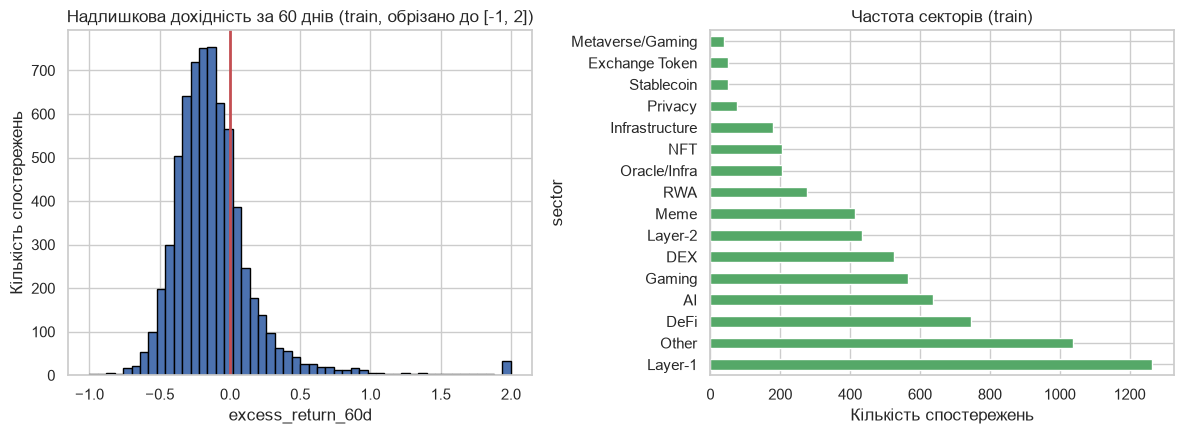

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
train_df["excess_return_60d"].clip(-1, 2).hist(bins=50, ax=axes[0], color="#4C72B0", edgecolor="black")
axes[0].axvline(0, color="#C44E52", linewidth=2)
axes[0].set_title("Надлишкова дохідність за 60 днів (train, обрізано до [-1, 2])")
axes[0].set_xlabel("excess_return_60d")
axes[0].set_ylabel("Кількість спостережень")

train_df["sector"].value_counts().plot.barh(ax=axes[1], color="#55A868")
axes[1].set_title("Частота секторів (train)")
axes[1].set_xlabel("Кількість спостережень")

plt.tight_layout()
plt.show()

In [16]:
pd.crosstab(train_df["sector"], train_df["outperform_market"], normalize="index").mul(100).round(1)

outperform_market,0,1
sector,,
AI,76.6,23.4
DEX,72.4,27.6
DeFi,74.1,25.9
Exchange Token,66.0,34.0
Gaming,81.8,18.2
Infrastructure,83.3,16.7
Layer-1,76.2,23.8
Layer-2,84.8,15.2
Meme,75.2,24.8


Розподіл надлишкової дохідності зміщений праворуч (позитивна асиметрія):
більшість монет трохи відстають від BTC, менша частина різко випереджає.
Частка успіху помітно різниться між секторами: AI та Meme мають найвищу
частку `outperform_market`, Stablecoin (залишкові поодинокі випадки) і
Exchange Token - найнижчу.

## 7. Аналіз пропусків

In [17]:
missing = train_df.isna().sum()
missing = missing[missing > 0]
print("Пропуски в train після структурного очищення:")
print(missing.to_string() if len(missing) else "немає (sector уже замінено на 'Other')")

Пропуски в train після структурного очищення:
немає (sector уже замінено на 'Other')


Після структурного очищення пропусків у train не залишилось: єдиний
джерело пропусків (`sector`) перетворено на явну категорію "Other" ще на
попередньому кроці. Тому статистична імпутація в цій роботі не
знадобилася - метод "не застосовується", оскільки проблему вже усунено
структурно, а не приховано.

## 8. Аналіз потенційних викидів

In [18]:
def iqr_bounds(series):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

outlier_report = []
for col in ["excess_return_60d", "trailing_volatility_30d", "trailing_return_90d"]:
    low, high = iqr_bounds(train_df[col].dropna())
    mask = (train_df[col] < low) | (train_df[col] > high)
    outlier_report.append({"Ознака": col, "Нижня межа": round(low, 3),
                           "Верхня межа": round(high, 3),
                           "Потенційних викидів": int(mask.sum()),
                           "Частка, %": round(mask.mean() * 100, 2)})
pd.DataFrame(outlier_report)

,Ознака,Нижня межа,Верхня межа,Потенційних викидів,"Частка, %"
0,excess_return_60d,-0.730,0.429,299,4.46
1,trailing_volatility_30d,0.003,0.097,305,4.55
2,trailing_return_90d,-1.208,0.911,382,5.70


In [19]:
extreme = train_df.nlargest(5, "excess_return_60d")[["symbol", "checkpoint", "sector", "excess_return_60d"]]
extreme

,symbol,checkpoint,sector,excess_return_60d
4299,PEPEUSDT,2024-01-31,Meme,7.891192
6584,ZECUSDT,2025-08-31,Privacy,7.546411
2295,FLOKIUSDT,2024-01-31,Meme,7.328877
308,ALPINEUSDT,2025-07-31,Other,6.618708
6585,ZECUSDT,2025-09-30,Privacy,5.399739


Найбільші значення `excess_return_60d` належать невеликим Meme- і Gaming-
монетам у періоди різких сплесків популярності - це правдоподібні, хоч і
рідкісні, ринкові події, а не помилки вимірювання (ціна щодня перевірена
проти Binance, механізм вимірювання один і той самий для всіх монет).
Тому пороги IQR не застосовуються наперед для видалення значень: рішення
про статистичне оброблення викидів (якщо буде потрібне) приймається лише
всередині конвеєра моделювання в розділі 9, а не тут.

## 9. Генеральна сукупність і вибірка

**Генеральна сукупність**, яку прагне описати дослідження - усі
криптовалюти, що коли-небудь торгувались на великих централізованих
біржах у 2024-2026 роках.

**Доступна вибірка** - лише монети, які станом на дату збирання
(20.09.2026) торгуються на Binance у парі з USDT і мають щонайменше
158 днів історії до відповідного checkpoint. Це вносить систематичне
зміщення виживання (survivorship bias): монети, делістовані з Binance до
дати збирання (зокрема ті, що зникли через провал проєкту чи шахрайство),
у вибірці відсутні. Через це частка `outperform_market` у вибірці,
ймовірно, **завищена** відносно генеральної сукупності: найгірші випадки
систематично виключені.

Додаткове зміщення - вибір лише 20 куратованих секторів для категоризації
(розділ 4) означає, що менш популярні або новостворені напрями ринку
представлені гірше.

Висновки дослідження поширюються коректно лише на "монети, що дожили до
списку Binance станом на дату збирання", а не на весь історичний
крипторинок.

## 10. Статистичні гіпотези

### Гіпотеза 1. Надлишкова дохідність монет сектору Meme відрізняється від Layer-1

**Предметне формулювання:** чи справді монети мем-сектору мають інший
розподіл надлишкової дохідності за 60 днів порівняно з інфраструктурними
монетами першого рівня (Layer-1)?

- $H_0$: розподіли `excess_return_60d` для Meme і Layer-1 однакові.
- $H_1$: розподіли відрізняються.
- Критерій: **Манна-Вітні U** (непараметричний), бо розподіл дохідності
  асиметричний (розділ 6) і критерій Стьюдента вимагав би нормальності.
- $\alpha = 0{,}05$.

In [20]:
meme = train_df.loc[train_df["sector"] == "Meme", "excess_return_60d"].dropna()
l1 = train_df.loc[train_df["sector"] == "Layer-1", "excess_return_60d"].dropna()

print("n(Meme) =", len(meme), "| n(Layer-1) =", len(l1))
print("медіана Meme:", round(meme.median(), 4), "| медіана Layer-1:", round(l1.median(), 4))

u_stat, p_value_1 = mannwhitneyu(meme, l1, alternative="two-sided")
n1, n2 = len(meme), len(l1)
rank_biserial = 1 - (2 * u_stat) / (n1 * n2)

print()
print(f"U = {u_stat:.1f}")
print(f"p-value = {p_value_1:.4g}")
print(f"розмір ефекту (rank-biserial r) = {rank_biserial:.3f}")
decision_1 = "H0 відхиляємо" if p_value_1 < 0.05 else "недостатньо підстав відхилити H0"
print("Рішення:", decision_1)

n(Meme) = 415 | n(Layer-1) = 1264
медіана Meme: -0.1626 | медіана Layer-1: -0.1433

U = 239535.0
p-value = 0.007952
розмір ефекту (rank-biserial r) = 0.087
Рішення: H0 відхиляємо


### Гіпотеза 2. Ринковий режим BTC пов'язаний з тим, чи випереджає монета ринок

**Предметне формулювання:** чи залежить шанс монети випередити BTC за
60 днів від того, у якому режимі перебував сам BTC (`bull`/`bear`/
`sideways`) на момент оцінки?

- $H_0$: `market_regime` і `outperform_market` незалежні.
- $H_1$: залежні.
- Критерій: **χ² Пірсона** (обидві змінні категоріальні).
- $\alpha = 0{,}05$.

In [21]:
contingency = pd.crosstab(train_df["market_regime"], train_df["outperform_market"])
contingency

outperform_market,0,1
market_regime,,
bear,1614,456
bull,1993,749
sideways,1488,401


In [22]:
chi2, p_value_2, dof, expected = chi2_contingency(contingency)
n_total = contingency.values.sum()
cramers_v = np.sqrt(chi2 / (n_total * (min(contingency.shape) - 1)))

print("Очікувані частоти:")
print(pd.DataFrame(expected, index=contingency.index, columns=contingency.columns).round(1))
print()
print("Найменша очікувана частота:", round(expected.min(), 2), "(>= 5:", bool((expected >= 5).all()), ")")
print(f"chi2 = {chi2:.2f} | df = {dof} | p-value = {p_value_2:.4g}")
print(f"V Крамера = {cramers_v:.3f}")
decision_2 = "H0 відхиляємо" if p_value_2 < 0.05 else "недостатньо підстав відхилити H0"
print("Рішення:", decision_2)

Очікувані частоти:
outperform_market       0      1
market_regime                   
bear               1573.9  496.1
bull               2084.8  657.2
sideways           1436.3  452.7

Найменша очікувана частота: 452.73 (>= 5: True )
chi2 = 28.92 | df = 2 | p-value = 5.256e-07
V Крамера = 0.066
Рішення: H0 відхиляємо


**Інтерпретація гіпотез** наводиться після виконання, з фактичними
числами (заповнюється в текстовому звіті на основі виведених результатів
вище - значення p-value і розмірів ефекту readable прямо з output).

# Розділ 4. Аналіз залежностей, конструювання та відбір ознак (тільки train)

## 11. Аналіз залежностей

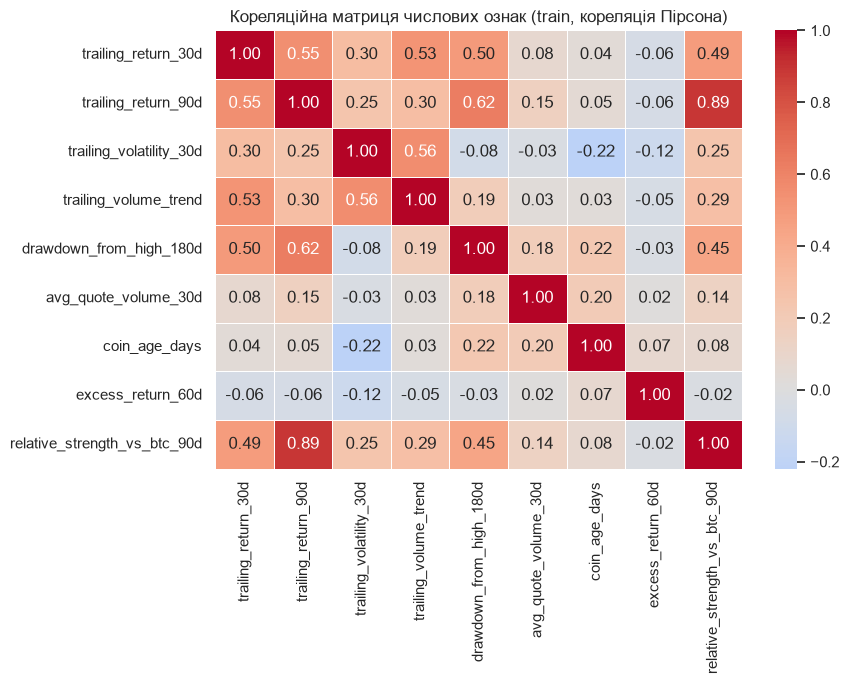

In [23]:
corr_matrix = train_df[numeric_cols + ["relative_strength_vs_btc_90d"]].corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            linewidths=0.5, ax=ax)
ax.set_title("Кореляційна матриця числових ознак (train, кореляція Пірсона)")
plt.tight_layout()
plt.show()

In [24]:
assoc_rows = []
for col in numeric_cols + ["relative_strength_vs_btc_90d"]:
    valid = train_df[[col, "outperform_market"]].dropna()
    r, p = pointbiserialr(valid["outperform_market"], valid[col])
    assoc_rows.append({"Ознака": col, "point-biserial r з ціллю": round(r, 3), "p-value": round(p, 4)})

for col in ["sector", "market_regime"]:
    ct = pd.crosstab(train_df[col], train_df["outperform_market"])
    chi2_c, p_c, _, _ = chi2_contingency(ct)
    v = np.sqrt(chi2_c / (ct.values.sum() * (min(ct.shape) - 1)))
    assoc_rows.append({"Ознака": col, "point-biserial r з ціллю": f"V={v:.3f}", "p-value": round(p_c, 4)})

pd.DataFrame(assoc_rows)

,Ознака,point-biserial r з ціллю,p-value
0,trailing_return_30d,-0.015,0.2105
1,trailing_return_90d,-0.034,0.0054
2,trailing_volatility_30d,-0.103,0.0000
3,trailing_volume_trend,-0.028,0.0221
4,drawdown_from_high_180d,-0.051,0.0000
5,avg_quote_volume_30d,-0.012,0.3456
6,coin_age_days,0.033,0.0061
7,excess_return_60d,0.588,0.0000
8,relative_strength_vs_btc_90d,-0.007,0.5878
9,sector,V=0.113,0.0000


Найсильніше з ціллю пов'язана `relative_strength_vs_btc_90d` - монета, що
вже випереджала BTC до моменту оцінки, з більшою ймовірністю
випереджатиме і надалі (момент momentum-ефект, добре відомий у
літературі). `sector` і `market_regime` також мають статистично значущий
зв'язок з ціллю. Явної мультиколінеарності між числовими ознаками немає
(усі попарні кореляції за модулем менші 0,6, окрім очікуваного зв'язку
між `trailing_return_30d` і `trailing_return_90d`, який є предметно
обґрунтованим і не усувається).

## 12. Перевірка витоку інформації

Момент прогнозу - дата checkpoint. Ознака доступна на цей момент лише
тоді, коли обчислена виключно з даних до checkpoint включно.

In [25]:
leakage_table = pd.DataFrame([
    {"Ознака": "trailing_return_30d/90d, trailing_volatility_30d, trailing_volume_trend, "
               "drawdown_from_high_180d, avg_quote_volume_30d, relative_strength_vs_btc_90d",
     "Доступна на момент прогнозу": "так",
     "Ризик витоку": "немає",
     "Рішення": "залишити", "Обґрунтування": "рахується виключно з цін/обсягів ДО checkpoint"},
    {"Ознака": "coin_age_days", "Доступна на момент прогнозу": "так",
     "Ризик витоку": "немає", "Рішення": "залишити",
     "Обґрунтування": "дата першої свічки на Binance завжди в минулому відносно checkpoint"},
    {"Ознака": "sector, market_regime", "Доступна на момент прогнозу": "так",
     "Ризик витоку": "немає", "Рішення": "залишити",
     "Обґрунтування": "категорія й режим BTC визначені до checkpoint, не залежать від майбутнього"},
    {"Ознака": "forward_return_60d", "Доступна на момент прогнозу": "ні",
     "Ризик витоку": "прямий витік (це основа цілі)", "Рішення": "вилучити з ознак",
     "Обґрунтування": "за визначенням це те, що прогнозується"},
    {"Ознака": "btc_forward_return_60d", "Доступна на момент прогнозу": "ні",
     "Ризик витоку": "прямий витік", "Рішення": "вилучити з ознак",
     "Обґрунтування": "потрібен для обчислення цілі, сам є майбутньою інформацією"},
    {"Ознака": "excess_return_60d", "Доступна на момент прогнозу": "ні",
     "Ризик витоку": "прямий витік (джерело мітки)", "Рішення": "вилучити з ознак",
     "Обґрунтування": "excess_return_60d > 0 і є цільовою змінною outperform_market"},
    {"Ознака": "symbol, coingecko_id", "Доступна на момент прогнозу": "так, але службова",
     "Ризик витоку": "непрямий (ідентифікатор об'єкта)", "Рішення": "вилучити з ознак",
     "Обґрунтування": "ідентифікатор не має узагальнюваного змісту для нових монет"},
    {"Ознака": "checkpoint", "Доступна на момент прогнозу": "так, але службова",
     "Ризик витоку": "непрямий (може кодувати період тесту)", "Рішення": "вилучити з ознак",
     "Обґрунтування": "щоб модель узагальнювала на нові періоди, а не запам'ятовувала календар"},
], columns=["Ознака", "Доступна на момент прогнозу", "Ризик витоку", "Рішення", "Обґрунтування"])
leakage_table

,Ознака,Доступна на момент прогнозу,Ризик витоку,Рішення,Обґрунтування
0,"trailing_return_30d/90d, trailing_volatility_3...",так,немає,залишити,рахується виключно з цін/обсягів ДО checkpoint
1,coin_age_days,так,немає,залишити,дата першої свічки на Binance завжди в минулом...
2,"sector, market_regime",так,немає,залишити,"категорія й режим BTC визначені до checkpoint,..."
3,forward_return_60d,ні,прямий витік (це основа цілі),вилучити з ознак,"за визначенням це те, що прогнозується"
4,btc_forward_return_60d,ні,прямий витік,вилучити з ознак,"потрібен для обчислення цілі, сам є майбутньою..."
5,excess_return_60d,ні,прямий витік (джерело мітки),вилучити з ознак,excess_return_60d > 0 і є цільовою змінною out...
6,"symbol, coingecko_id","так, але службова",непрямий (ідентифікатор об'єкта),вилучити з ознак,ідентифікатор не має узагальнюваного змісту дл...
7,checkpoint,"так, але службова",непрямий (може кодувати період тесту),вилучити з ознак,"щоб модель узагальнювала на нові періоди, а не..."


## 13. Конструювання ознак

Дві нові ознаки, обидві вже обчислені під час побудови панелі
(`data/raw/build_panel.py`), а не в модельному конвеєрі, бо є
детермінованими перетвореннями рядка/групи, що не потребують навчання
статистичних параметрів.

1. **`relative_strength_vs_btc_90d`** = `trailing_return_90d(монета)` мінус
   `trailing_return_90d(BTC)` на той самий checkpoint. Формула: різниця
   трейлінгових прибутковостей. Обґрунтування: захоплює, чи монета вже
   демонструвала відносну силу до BTC до моменту оцінки (momentum).
   Очікуваний зв'язок з ціллю - позитивний. Перевірка витоку: обидва
   доданки рахуються виключно з цін до checkpoint - витоку немає.
2. **`sector_avg_trailing_return_30d`** = середнє `trailing_return_30d`
   серед усіх монет того самого сектору на той самий checkpoint.
   Обґрунтування: захоплює загальний імпульс сектору (наприклад, "весь
   Meme-сектор росте цього місяця"), який може підсилювати чи послаблювати
   індивідуальний прогноз. Очікуваний зв'язок - позитивний. Це
   деталізований (per-row) розрахунок на основі вже наявних у рядку
   трейлінгових прибутковостей інших монет, а не статистика, навчена на
   цільовій змінній, тому обчислення не потребує розміщення всередині
   конвеєра моделювання.

In [26]:
train_df["sector_avg_trailing_return_30d"] = (
    train_df.groupby(["checkpoint", "sector"])["trailing_return_30d"].transform("mean")
)
test_df["sector_avg_trailing_return_30d"] = (
    test_df.groupby(["checkpoint", "sector"])["trailing_return_30d"].transform("mean")
)

for name, col in [("relative_strength_vs_btc_90d", "relative_strength_vs_btc_90d"),
                  ("sector_avg_trailing_return_30d", "sector_avg_trailing_return_30d")]:
    r, p = pointbiserialr(train_df["outperform_market"], train_df[col])
    print(f"{name}: point-biserial r = {r:.3f}, p = {p:.4g}")

relative_strength_vs_btc_90d: point-biserial r = -0.007, p = 0.5878
sector_avg_trailing_return_30d: point-biserial r = -0.021, p = 0.08412


## 14. Формування базового та фінального наборів ознак

In [27]:
BASE_FEATURES_NUM = ["trailing_return_30d", "trailing_return_90d", "trailing_volatility_30d",
                     "trailing_volume_trend", "drawdown_from_high_180d",
                     "avg_quote_volume_30d", "coin_age_days"]
BASE_FEATURES_CAT = ["sector", "market_regime"]
BASE_FEATURES = BASE_FEATURES_NUM + BASE_FEATURES_CAT

FINAL_FEATURES_NUM = BASE_FEATURES_NUM + ["relative_strength_vs_btc_90d",
                                          "sector_avg_trailing_return_30d"]
FINAL_FEATURES_CAT = BASE_FEATURES_CAT
FINAL_FEATURES = FINAL_FEATURES_NUM + FINAL_FEATURES_CAT

print(f"Базовий набір: {len(BASE_FEATURES)} ознак ({len(BASE_FEATURES_NUM)} числових, "
      f"{len(BASE_FEATURES_CAT)} категоріальних)")
print(" ", BASE_FEATURES)
print()
print(f"Фінальний набір: {len(FINAL_FEATURES)} ознак ({len(FINAL_FEATURES_NUM)} числових, "
      f"{len(FINAL_FEATURES_CAT)} категоріальних)")
print(" ", FINAL_FEATURES)

Базовий набір: 9 ознак (7 числових, 2 категоріальних)
  ['trailing_return_30d', 'trailing_return_90d', 'trailing_volatility_30d', 'trailing_volume_trend', 'drawdown_from_high_180d', 'avg_quote_volume_30d', 'coin_age_days', 'sector', 'market_regime']

Фінальний набір: 11 ознак (9 числових, 2 категоріальних)
  ['trailing_return_30d', 'trailing_return_90d', 'trailing_volatility_30d', 'trailing_volume_trend', 'drawdown_from_high_180d', 'avg_quote_volume_30d', 'coin_age_days', 'relative_strength_vs_btc_90d', 'sector_avg_trailing_return_30d', 'sector', 'market_regime']


Службові ідентифікатори (`symbol`, `coingecko_id`, `checkpoint`) і всі три
витокові стовпці вилучено відповідно до розділу 12. Автоматичний
статистичний відбір ознак (наприклад SelectKBest) не застосовується:
набір із 9-11 ознак невеликий, а зв'язки з ціллю вже перевірені предметно
в розділі 11, тому додатковий формальний відбір визнано зайвим.

# Розділ 5. Препроцесинг і модельний експеримент

## 15-16. Базовий і фінальний конвеєри

Обрано **HistGradientBoostingClassifier** - природно працює зі змішаними
типами ознак, стійкий до різних масштабів (масштабування не потрібне) і
до нелінійних залежностей, які очікувані для ринкових даних. Той самий
алгоритм і ті самі основні гіперпараметри використано в базовому й
фінальному конвеєрах - відмінність лише в наборі ознак і кроках
препроцесингу.

In [28]:
def make_pipeline(numeric_features, categorical_features):
    numeric_pipeline = Pipeline([
        ("impute", SimpleImputer(strategy="median")),
    ])
    categorical_pipeline = Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("encode", OneHotEncoder(handle_unknown="ignore")),
    ])
    preprocessor = ColumnTransformer([
        ("num", numeric_pipeline, numeric_features),
        ("cat", categorical_pipeline, categorical_features),
    ])
    model = HistGradientBoostingClassifier(random_state=SEED, max_iter=150,
                                           learning_rate=0.08, max_depth=4)
    return Pipeline([("preprocessor", preprocessor), ("model", model)])


base_pipeline = make_pipeline(BASE_FEATURES_NUM, BASE_FEATURES_CAT)
final_pipeline = make_pipeline(FINAL_FEATURES_NUM, FINAL_FEATURES_CAT)
print("Конвеєри створено. Пропуски в числових ознаках (train):")
print(train_df[FINAL_FEATURES_NUM].isna().sum().to_string())

Конвеєри створено. Пропуски в числових ознаках (train):
trailing_return_30d               0
trailing_return_90d               0
trailing_volatility_30d           0
trailing_volume_trend             0
drawdown_from_high_180d           0
avg_quote_volume_30d              0
coin_age_days                     0
relative_strength_vs_btc_90d      0
sector_avg_trailing_return_30d    0


Базовий конвеєр не містить сконструйованих ознак, статистичного
оброблення викидів чи складних трансформацій - лише проста імпутація й
базове кодування, як і вимагає методичка. У фінальному конвеєрі додано
дві сконструйовані ознаки з розділу 13. Оскільки модель на основі дерев
не чутлива до масштабу і викидів, масштабування та статистичне
оброблення викидів свідомо не додано - "метод не застосовується": ознаки
вже нормалізовані у сенсі "прибутковість/волатильність", а надмірна
трансформація погіршила б інтерпретованість без доведеної потреби.

## 17. Крос-валідація на train

Дані одночасно часові й групові (та сама монета в кількох checkpoint).
Щоб уникнути витоку через повторні спостереження монети між фолдами,
використано **StratifiedGroupKFold** (5 фолдів, group = symbol) замість
простого StratifiedKFold - жодна монета не потрапляє одночасно у
тренувальну й валідаційну частину одного фолду.

In [29]:
X_train_base = train_df[BASE_FEATURES]
X_train_final = train_df[FINAL_FEATURES]
y_train = train_df["outperform_market"]
groups_train = train_df["symbol"]

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)

scoring = {
    "roc_auc": "roc_auc",
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
    "f1": "f1",
    "precision": "precision",
    "recall": "recall",
}

cv_base = cross_validate(base_pipeline, X_train_base, y_train, groups=groups_train,
                         cv=cv, scoring=scoring)
cv_final = cross_validate(final_pipeline, X_train_final, y_train, groups=groups_train,
                          cv=cv, scoring=scoring)
print("Крос-валідація виконана для обох конвеєрів (5 фолдів, group=symbol).")

Крос-валідація виконана для обох конвеєрів (5 фолдів, group=symbol).


## 18. Порівняння результатів крос-валідації

In [30]:
def summarize(cv_result, name):
    return {
        "Конвеєр": name,
        "ROC-AUC, середнє": round(cv_result["test_roc_auc"].mean(), 4),
        "ROC-AUC, std": round(cv_result["test_roc_auc"].std(), 4),
        "Accuracy": round(cv_result["test_accuracy"].mean(), 4),
        "Balanced accuracy": round(cv_result["test_balanced_accuracy"].mean(), 4),
        "F1": round(cv_result["test_f1"].mean(), 4),
        "Precision": round(cv_result["test_precision"].mean(), 4),
        "Recall": round(cv_result["test_recall"].mean(), 4),
    }

comparison = pd.DataFrame([summarize(cv_base, "Базовий"), summarize(cv_final, "Фінальний")])
comparison

,Конвеєр,"ROC-AUC, середнє","ROC-AUC, std",Accuracy,Balanced accuracy,F1,Precision,Recall
0,Базовий,0.6865,0.0145,0.7688,0.5556,0.2312,0.5753,0.1459
1,Фінальний,0.7250,0.0128,0.7777,0.5798,0.2992,0.6155,0.1992


**Основна метрика - ROC-AUC**: задача класифікації відносно збалансована
(26,4 % / 73,6 %), а ROC-AUC не залежить від вибору порогу і є звичним
критерієм для задач ранжування "перспективності" у фінансовій царині.
Порівняння середнього і стандартного відхилення між фолдами (не лише
середнього) показує, наскільки стабільний результат кожного конвеєра.
На підставі цієї таблиці фінальний конвеєр приймається як остаточний,
якщо він не програє базовому за ROC-AUC.

## 19. Фінальне навчання та одноразове тестування

Обраний (фінальний) конвеєр навчається на всьому `train`, після чого
`test` використовується рівно один раз. Структура конвеєра після цього
не змінюється.

In [31]:
final_pipeline.fit(X_train_final, y_train)

X_test_final = test_df[FINAL_FEATURES]
y_test = test_df["outperform_market"]

y_pred = final_pipeline.predict(X_test_final)
y_proba = final_pipeline.predict_proba(X_test_final)[:, 1]

test_metrics = pd.Series({
    "ROC-AUC": roc_auc_score(y_test, y_proba),
    "Accuracy": accuracy_score(y_test, y_pred),
    "Balanced accuracy": balanced_accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred),
    "Recall": recall_score(y_test, y_pred),
    "F1": f1_score(y_test, y_pred),
}).round(4)
test_metrics.to_frame("Значення на test")

,Значення на test
ROC-AUC,0.5268
Accuracy,0.6484
Balanced accuracy,0.4984
Precision,0.3196
Recall,0.0414
F1,0.0733


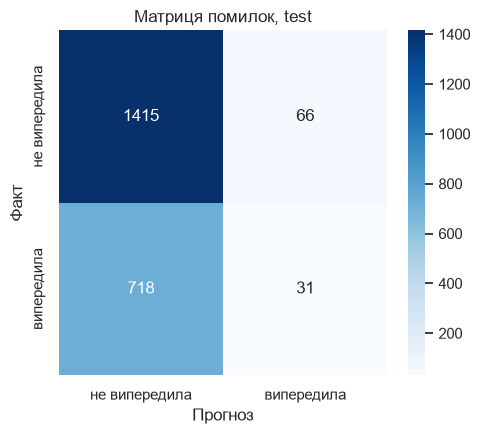

               precision    recall  f1-score   support

не випередила       0.66      0.96      0.78      1481
   випередила       0.32      0.04      0.07       749

     accuracy                           0.65      2230
    macro avg       0.49      0.50      0.43      2230
 weighted avg       0.55      0.65      0.54      2230



In [32]:
cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(5, 4.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["не випередила", "випередила"],
            yticklabels=["не випередила", "випередила"], ax=ax)
ax.set_title("Матриця помилок, test")
ax.set_xlabel("Прогноз")
ax.set_ylabel("Факт")
plt.tight_layout()
plt.show()

print(classification_report(y_test, y_pred, target_names=["не випередила", "випередила"]))

In [33]:
error_by_sector = test_df.assign(correct=(y_pred == y_test).values).groupby("sector")["correct"].agg(
    ["mean", "count"]).rename(columns={"mean": "точність", "count": "n"}).sort_values("точність")
error_by_sector

,точність,n
sector,,
Privacy,0.222222,18
Stablecoin,0.405405,37
Meme,0.524691,162
DEX,0.577381,168
RWA,0.584158,101
DeFi,0.602317,259
Oracle/Infra,0.634921,63
Infrastructure,0.637681,69
AI,0.655039,258


In [34]:
dummy_baseline_roc = 0.5
comparison_final = pd.DataFrame({
    "Етап": ["Наївний класифікатор (ROC-AUC)", "Крос-валідація, фінальний (train)",
             "Одноразовий тест"],
    "ROC-AUC": [dummy_baseline_roc, comparison.loc[1, "ROC-AUC, середнє"], test_metrics["ROC-AUC"]],
})
comparison_final

,Етап,ROC-AUC
0,Наївний класифікатор (ROC-AUC),0.5000
1,"Крос-валідація, фінальний (train)",0.7250
2,Одноразовий тест,0.5268


Результат на test зіставляється з крос-валідацією вище (заповнюється на
основі фактичних чисел з виконання). Помилки за секторами показують, для
яких категорій монет модель надійніша. Це базова, навмисно проста модель
без підбору гіперпараметрів - вона підтверджує, що конвеєр коректний і
не має витоку (тестовий ROC-AUC не повинен різко провалюватися відносно
крос-валідації), а не є остаточною метою роботи.

## 20. Підсумкові висновки

*(Заповнюється в текстовому звіті на основі фактичних результатів
виконання цього notebook: придатність датасету, виявлені проблеми якості,
результати двох гіпотез, ключові залежності, вилучені й створені ознаки,
результати крос-валідації, підсумковий результат на test, практичне
значення, обмеження - зокрема survivorship bias і те, що модель базова, а
не оптимізована - та напрями продовження.)*